# Module 04 Homework

In [112]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

In [46]:
data_path = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/refs/heads/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(data_path)

In [47]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


Fill missing categorical values with 'NA' and numerical values with 0

In [49]:
categorical_cols = df.select_dtypes(include=['string']).columns.to_list()
categorical_cols

['lead_source', 'industry', 'employment_status', 'location']

In [50]:
numerical_cols = (
    df
    .select_dtypes(include=['number'])
    .columns
    .to_list()
)

numerical_cols.remove('converted')
numerical_cols

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [51]:
df[categorical_cols] = df[categorical_cols].fillna('NA')
df[numerical_cols] = df[numerical_cols].fillna(0)

In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               5000 non-null   str    
 1   industry                  5000 non-null   str    
 2   employment_status         5000 non-null   str    
 3   location                  5000 non-null   str    
 4   annual_income             5000 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                5000 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


Prepare training, validation, and test splits

In [53]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [54]:
auc_scores = {}

for col in numerical_cols:
    x = df_train[col].values
    y = df_train['converted'].values
    auc_score = roc_auc_score(y, x)

    if auc_score < 0.5:
        auc_score = roc_auc_score(y, -x)
    auc_scores[col] = auc_score

In [55]:
auc_scores

{'annual_income': 0.6081977776250831,
 'number_of_courses_viewed': 0.7229894623989618,
 'interaction_count': 0.7649203047563227,
 'lead_score': 0.7882254810906102}

### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832

In [68]:
X_train = df_train.drop(columns=['converted'])
y_train = df_train['converted'].values

In [70]:
X_val = df_val.drop(columns=['converted'])
y_val = df_val['converted'].values

In [71]:
dv = DictVectorizer(sparse=False)
X_train_dict = X_train.to_dict(orient='records')
X_train_encoded = dv.fit_transform(X_train_dict)

In [73]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train_encoded, y_train)


,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [76]:
X_val_encoded = dv.transform(X_val.to_dict(orient='records'))
y_pred_proba = model.predict_proba(X_val_encoded)[:, -1]

In [77]:
roc_auc_score(y_val, y_pred_proba)

0.7318222288173319

### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83

In [101]:
thresholds = np.arange(0.00, 1.01, 0.01).tolist()

In [106]:
scores = []

for t in thresholds:
    y_pred = (y_pred_proba >= t).astype(int)
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)
    #print(f"Threshold: {t:.2f}, Precision: {precision:.3f}, Recall: {recall:.3f}")
    scores.append({'threshold': t, 'precision': precision, 'recall': recall, 'f1': f1})


In [107]:
df_scores = pd.DataFrame(scores)
df_scores.head()

,threshold,precision,recall,f1
0,0.00,0.586,1.0,0.738966
1,0.01,0.586,1.0,0.738966
2,0.02,0.586,1.0,0.738966
3,0.03,0.586,1.0,0.738966
4,0.04,0.586,1.0,0.738966


<Axes: xlabel='threshold'>

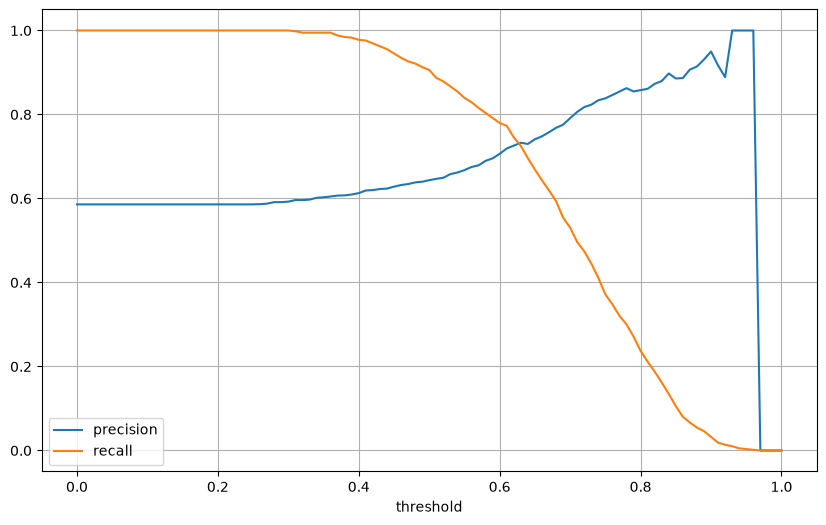

In [108]:
df_scores.plot(x='threshold', y=['precision', 'recall'], figsize=(10, 6), grid=True)

### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

<Axes: xlabel='threshold'>

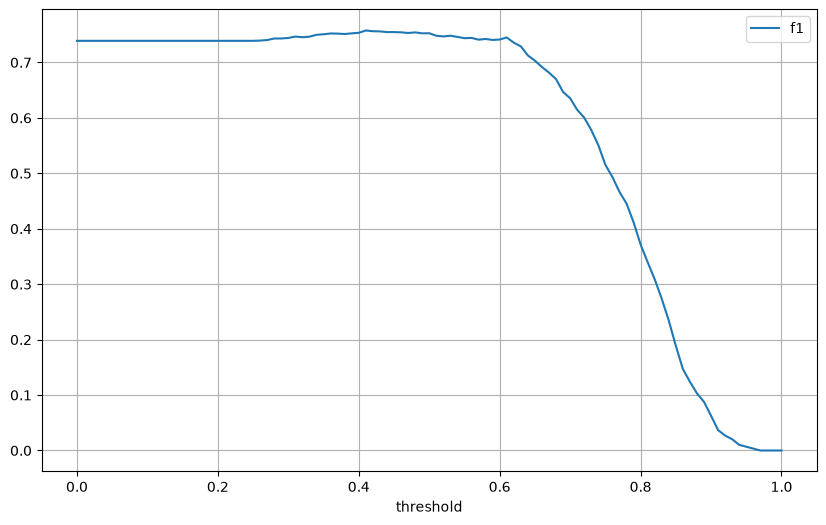

In [109]:
df_scores.plot(x='threshold', y='f1', figsize=(10, 6), grid=True)

In [111]:
df_scores.loc[df_scores['f1'].idxmax()]

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [113]:
fold = KFold(n_splits=5, shuffle=True, random_state=1)

In [114]:
kfold_scores = []

for train_idx, val_idx in fold.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    X_train_fold = df_train_fold.drop(columns=['converted'])
    y_train_fold = df_train_fold['converted'].values

    X_val_fold = df_val_fold.drop(columns=['converted'])
    y_val_fold = df_val_fold['converted'].values

    dv = DictVectorizer(sparse=False)
    X_train_dict = X_train_fold.to_dict(orient='records')
    X_train_encoded = dv.fit_transform(X_train_dict)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train_encoded, y_train_fold)

    X_val_encoded = dv.transform(X_val_fold.to_dict(orient='records'))
    y_pred_proba = model.predict_proba(X_val_encoded)[:, -1]

    score = roc_auc_score(y_val_fold, y_pred_proba)
    kfold_scores.append(score)

In [115]:
np.std(kfold_scores)

np.float64(0.006853233151022138)

### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

In [116]:
C_values = [0.000001, 0.001, 1]
C_scores = []

for C in C_values:
    kfold_scores = []

    for train_idx, val_idx in fold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        X_train_fold = df_train_fold.drop(columns=['converted'])
        y_train_fold = df_train_fold['converted'].values

        X_val_fold = df_val_fold.drop(columns=['converted'])
        y_val_fold = df_val_fold['converted'].values

        dv = DictVectorizer(sparse=False)
        X_train_dict = X_train_fold.to_dict(orient='records')
        X_train_encoded = dv.fit_transform(X_train_dict)

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_train_encoded, y_train_fold)

        X_val_encoded = dv.transform(X_val_fold.to_dict(orient='records'))
        y_pred_proba = model.predict_proba(X_val_encoded)[:, -1]

        score = roc_auc_score(y_val_fold, y_pred_proba)
        kfold_scores.append(score)

    C_scores.append({'C': C, 'mean_auc': np.mean(kfold_scores), 'std_auc': np.std(kfold_scores)})

In [117]:
df_c_scores = pd.DataFrame(C_scores)

In [118]:
df_c_scores

,C,mean_auc,std_auc
0,0.000001,0.616734,0.018670
1,0.001000,0.749172,0.009996
2,1.000000,0.731727,0.006853
